# Fraudes em transações e priorização econômica de análises
## Projeto final de Aprendizado de Máquina — IBMEC
**Professor:** Marcelo Guzella. **Autor(a):** inserir nome completo antes da submissão.

**Pergunta:** com a mesma capacidade diária de investigação, o modelo identifica maior valor de transações fraudulentas que regras simples?

Este projeto é separado do M5. Dados reais da IEEE-CIS/Vesta permitem medir o valor rotulado identificado. A economia depende de hipóteses sobre custo e eficácia da investigação; não se trata de lucro realizado.

**Navegação:** seções 1–18 apresentam o experimento; 19–23 concentram comparação, demonstração, defesa e reprodutibilidade. O notebook tem resultados executados. Para refazer os treinamentos, altere `REEXECUTAR=True`; para apresentação, use o modo de leitura ou a célula de demonstração.

## 0. Como estudar este notebook
Este material tem dois usos: **reproduzir o experimento** e **aprender a defendê-lo**. Leia cada seção nesta ordem: problema → explicação → código → resultado → interpretação. O código principal reutiliza funções de `src/experiment.py`; isso evita divergência entre o notebook e o experimento. Abaixo acrescentamos pequenos cálculos executáveis para tornar visíveis as decisões centrais.

**Não precisa decorar tudo:** domine o objetivo, o que cada bloco pode aprender, as métricas, a construção da fila e a conta financeira. Consulte os detalhes de implementação no código quando necessário.

As saídas do experimento original são preservadas. As novas células didáticas recalculam exemplos e verificam números sem escolher novos vencedores ou reajustar modelos. Valores monetários nas explicações usam convenção brasileira; saídas Python podem usar ponto decimal.

**Mapa de apresentação de 12 minutos:** problema e base (2 min), preparação e protocolo (2 min), técnicas e avaliação (3 min), fila e ganho financeiro (3 min), limites e conclusão (2 min). O notebook é mais extenso porque também sustenta as perguntas após os slides.

## 1. Decisão de negócio e critério de sucesso
Uma equipe limitada não consegue revisar todas as transações. A pergunta relevante é quais casos colocar na fila. A política principal prioriza **probabilidade de fraude × valor**, respeitando um orçamento diário de revisão de 2% das transações da amostra.

Comparamos essa política com sorteio, maiores valores e taxa histórica por categoria de produto multiplicada pelo valor. A referência principal é escolhida na validação. Não comparamos apenas com “não fazer nada”, que seria uma referência fraca.

**Sucesso predefinido:** identificar mais valor rotulado com o mesmo número de análises e apresentar benefício incremental positivo no teste sob hipóteses transparentes. O intervalo por blocos e os cenários avaliam se a conclusão é frágil.

### Passo a passo: transformar um problema em uma decisão
1. **Unidade:** uma transação. Não estamos prevendo se uma pessoa é fraudadora.
2. **Informação disponível:** atributos da transação no momento de colocá-la na fila.
3. **Previsão:** probabilidade de o rótulo dessa transação ser fraude.
4. **Decisão:** quais transações investigar, considerando a capacidade diária.
5. **Avaliação:** depois de selecionar, consultar os rótulos e somar o valor das fraudes selecionadas.

O modelo gera um score; a política transforma esse score em uma ação. Esses dois objetos têm avaliações diferentes. Um modelo pode acertar mais fraudes pequenas e identificar menos dinheiro que outro.

**Exemplo para explicar oralmente:** A tem 80% de risco e valor de US$ 10; B tem 20% de risco e valor de US$ 1.000. A exposição esperada é US$ 8 em A e US$ 200 em B. Com capacidade para apenas uma análise, a política monetária escolhe B. Isso não garante que B seja fraude: é uma decisão sob incerteza.

**Resposta de defesa:** “Nosso objetivo não é maximizar acurácia. É melhorar a seleção de uma fila limitada e medir quanto valor de fraude essa fila identifica.”

In [1]:
from pathlib import Path
import sys,os,json
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'Projeto_Fraude'] if (p/'references'/'openml_metadata.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from experiment import NUM,CAT,CONFIG,run,preprocess,specs,budget_sample,review_mask,financial,cls_metrics,reg_metrics
import numpy as np,pandas as pd
from IPython.display import display,Image
pd.set_option('display.max_columns',20)
pd.set_option('display.precision',4)
REEXECUTAR=False
if REEXECUTAR:
    run()
def read(name):return pd.read_csv(ROOT/'results'/name)
def meta(name):return json.loads((ROOT/'results'/name).read_text())
def figure(name):display(Image(filename=str(ROOT/'results/figures'/f'{name}.png')))
d=pd.read_parquet(ROOT/'data/processed/transactions.parquet')
print('Linhas:',len(d),'| atributos:',len(NUM)+len(CAT))
display(pd.DataFrame([meta('execution.json')]))

Linhas: 116533 | atributos: 71


,python,numpy,pandas,sklearn,duration_seconds,classification_winner,regression_winner,checks,techniques
0,3.9.6,2.0.2,2.3.3,1.6.1,162.769,ExtraTrees,RandomForest,125,19


## 2. Origem, arquivos e significado da base
A IEEE-CIS Fraud Detection foi disponibilizada por Vesta e IEEE-CIS no Kaggle. O conjunto público rotulado possui 590.540 transações e 20.663 fraudes. `isFraud` é o rótulo, `TransactionAmt` informa valor e `TransactionDT` é um deslocamento temporal em segundos. Ele não fornece uma data civil conhecida.

Baixamos o espelho OpenML 46858, indicado pelo projeto Empulse. O parquet preserva `TransactionDT`, mas não `TransactionID`. Criamos `source_row`, um identificador de linha sem uso preditivo. O espelho contém 456 campos, incluindo variantes de nomes de atributos de identidade. Utilizamos uma lista predefinida de 71 atributos, não todos os campos nem os identificadores.

Atributos C, D, V e parte de id são anonimizados. Conhecemos famílias gerais, mas não podemos inventar o significado de cada coluna. A disponibilização pública de um atributo não demonstra, sozinha, que seu cálculo original estava livre de informação futura; essa é uma limitação de proveniência.

Fontes: [competição](https://www.kaggle.com/competitions/ieee-fraud-detection/data), [metadados OpenML](https://www.openml.org/d/46858), [documentação Empulse](https://empulse.readthedocs.io/en/latest/guide/datasets/ieee_fraud_detection.html). Os hashes registram os arquivos locais. O MD5 nos metadados se refere ao ARFF, não ao parquet baixado; não alegamos que o verificamos contra o parquet.

### Passo a passo: conhecer a base antes de modelar
Leia primeiro a origem e depois a unidade de cada campo. `TransactionAmt` é um valor em dólares; `isFraud` é uma variável binária, com 1 para fraude; `TransactionDT` ordena eventos por um deslocamento em segundos. Nenhum desses campos prova o prejuízo líquido da instituição.

Uma base pública de competição é adequada para testar métodos com rótulos conhecidos. Ela não equivale à base operacional completa de uma empresa. O espelho é uma forma de acesso: preservamos sua origem e o hash do arquivo, sem tratar o OpenML como o produtor original dos eventos.

**Como ler a auditoria a seguir:** procure quantidade de linhas, fraudes, colunas originais e linhas usadas. São universos diferentes: arquivo original, amostra de avaliação e amostra usada em cada ajuste. Não use “treinamos com 590 mil transações” para descrever um ajuste limitado a 30 mil.

**Se perguntarem o significado de V130:** “É um atributo anonimizado. Posso explicar seu tratamento e sua importância estatística, mas a documentação disponível não permite dar um significado de negócio específico.”

In [2]:
audit=meta('audit.json')
display(pd.DataFrame([{k:v for k,v in audit.items() if not isinstance(v,list)}]).T.rename(columns={0:'valor'}))
display(pd.DataFrame([meta('provenance.json')]))

,valor
raw_rows,590540
raw_frauds,20663
raw_fields,456
raw_time_min,86400
raw_time_max,15811131
raw_missing_fraction,0.3111
transaction_id_present,False
sample_rows,116533
sample_frauds,4046
sample_fraction,0.1973


,original,mirror,openml_id,loader_reference,sha256,bytes,note
0,https://www.kaggle.com/competitions/ieee-fraud...,https://data.openml.org/datasets/0004/46858/da...,46858,https://empulse.readthedocs.io/en/latest/guide...,c313ad335223589693e26d5808267ed6ff03d871be5d9b...,78250805,"Local parquet hash; OpenML MD5 refers to ARFF,..."


## 3. Unidade de análise, amostra e limites
Uma linha é uma transação, não um cliente. Selecionamos uma em cada cinco linhas do arquivo, sem olhar classe ou valor, e excluímos os dois dias extremos para evitar orçamentos em dias parciais. A amostra tem 116.533 transações e 4.046 fraudes.

O orçamento operacional vale para essa amostra e não corresponde automaticamente à capacidade da empresa inteira. O sorteio de treino usa no máximo 30 mil linhas por ajuste, sem reequilibrar artificialmente as classes. Isso torna viável comparar dezenove técnicas. Todos os algoritmos recebem a mesma amostra de cada bloco autorizado. A avaliação usa todas as linhas dos respectivos blocos da amostra sistemática.

Não há chave confiável de cliente para impedir que o mesmo indivíduo apareça em períodos diferentes. O teste temporal avalia um fluxo posterior, não generalização a clientes inéditos. Valores e taxas não podem ser extrapolados para todo o mercado.

### Passo a passo: por que reduzir a base?
A seleção sistemática conserva aproximadamente um quinto das linhas e torna o estudo executável. Como o critério é a posição da linha, ele não favorece intencionalmente fraude ou valores altos. Contudo, não é uma amostra aleatória simples: se a ordenação tivesse periodicidade relacionada ao risco, poderia introduzir viés. Por isso, não afirmamos representatividade garantida.

Há duas reduções diferentes: a amostra sistemática define o universo deste estudo; o limite de 30 mil reduz o custo de cada treinamento. O teste mantém todas as transações da amostra no seu intervalo, sem escolher apenas os casos fáceis.

**Leia a tabela:** `start` e `end` indicam o intervalo temporal; as quantidades mostram o peso de cada bloco. Compare a prevalência entre blocos: mudança na frequência de fraude pode afetar probabilidades e métricas.

**Resposta de defesa:** “Usamos a mesma regra de amostragem e os mesmos períodos para comparar os modelos. Uma extensão seria repetir o estudo em outras amostras e na base completa.”

In [3]:
display(pd.DataFrame(audit['splits']).sort_values('start'))
display(d[['source_row','TransactionDT','day','TransactionAmt','isFraud','exposure','split']].head())
assert not d.source_row.duplicated().any()
assert np.allclose(d.exposure,d.TransactionAmt*d.isFraud)

,split,n,days,start,end,frauds,amount
2,train,74365,107,1,107,2532,362072.718
3,validation,16370,27,108,134,649,116548.887
0,calibration,9883,18,135,152,335,49492.762
1,test,15915,28,153,180,530,78851.255


,source_row,TransactionDT,day,TransactionAmt,isFraud,exposure,split
0,5125,172857,1,117.00,0,0.0,train
1,5130,172951,1,57.95,0,0.0,train
2,5135,173025,1,50.00,0,0.0,train
3,5140,173132,1,40.95,0,0.0,train
4,5145,173189,1,35.00,0,0.0,train


## 4. Limpeza e preparação
Ausências podem ser informativas: dados de dispositivo nem sempre existem. Valores numéricos ausentes recebem mediana aprendida no treino, e indicadores adicionais registram a ausência. Categorias ausentes recebem uma categoria explícita. Categorias raras são agrupadas e categorias novas não interrompem a previsão.

One-hot encoding evita impor ordem a códigos de cartão, região e produto. Padronização reduz diferenças de escala em regressões regularizadas e KNN. Árvores não precisam de escala, mas usamos o mesmo pipeline para comparação consistente. Preços extremos não são apagados apenas por serem grandes: podem representar exposição relevante.

A fração de ausência registrada na auditoria refere-se aos campos efetivamente lidos, e não necessariamente a todos os 456 campos do espelho. Não interpretamos códigos anônimos como variáveis pessoais identificadas.

### Passo a passo: o que o pré-processamento aprende?
**Imputação:** se os valores de treino são 10, 20 e ausente, a mediana dos observados é 15. O ausente recebe 15. No teste, usamos essa mediana já aprendida; não recalculamos com o futuro.

**Indicador de ausência:** registra que o valor original não estava disponível. Isso diferencia um 15 observado de um 15 imputado, quando o indicador existe no pipeline.

**One-hot:** uma categoria como ProductCD=W vira uma coluna indicadora, não o número ordinal “5”. Cartões e regiões codificados são tratados como categorias quando assim definidos na lista CAT.

**Padronização:** subtrai a média e divide pelo desvio do treino. Em KNN, isso impede que uma variável domine a distância apenas por sua unidade. Em regularização, torna a penalização mais comparável entre variáveis.

**Pipeline:** encadeia as transformações e o estimador. Cada fold executa `fit` apenas no passado e `predict` no bloco posterior. Preencher ausências em toda a base antes da validação contaminaria a comparação.

**Cuidado ao ler:** ausência alta não determina remoção automática. Primeiro verificamos se a informação disponível é útil e coerente com o momento da decisão.

,feature,missing_fraction
23,D7,0.9369
2,dist2,0.9269
29,D13,0.8953
30,D14,0.8920
28,D12,0.8879
22,D6,0.8752
24,D8,0.8609
25,D9,0.8609
43,V150,0.8344
60,R_emaildomain,0.7464


Alvos fora das entradas: True
Fraudes no treino: 0.03404827539837289


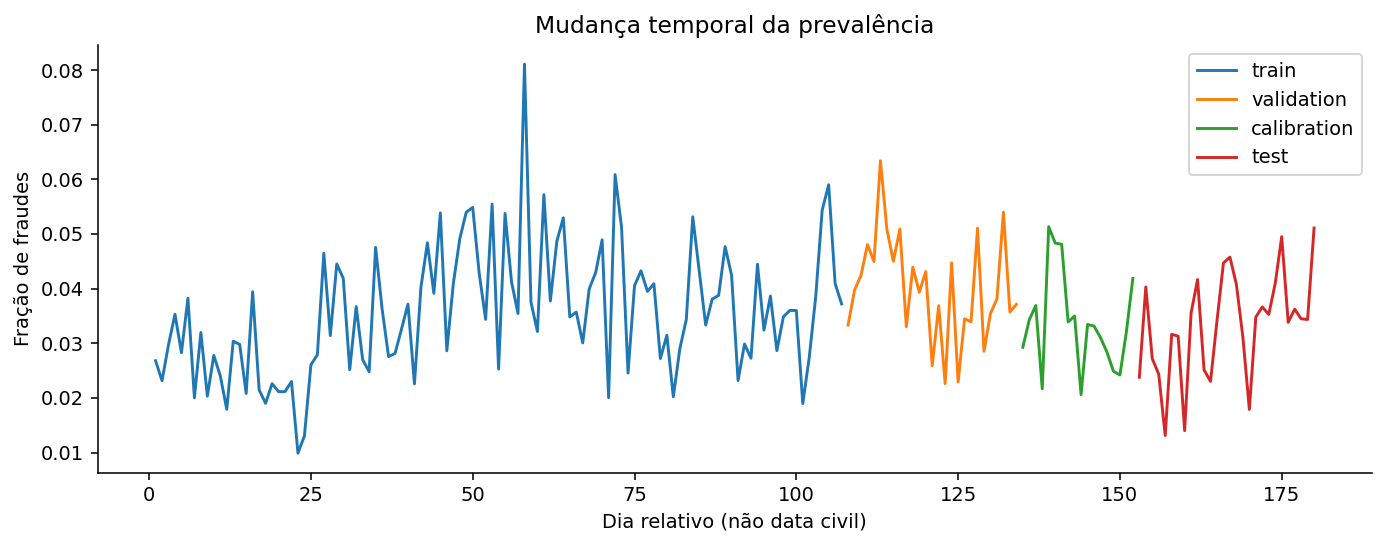

In [4]:
display(read('missing_features.csv').sort_values('missing_fraction',ascending=False).head(20))
print('Alvos fora das entradas:',not {'isFraud','exposure','day','TransactionDT','source_row'}.intersection(NUM+CAT))
print('Fraudes no treino:',d.loc[d.split=='train','isFraud'].mean())
figure('timeline')

## 5. Engenharia de atributos e prevenção de vazamento
Usamos valor da transação, distâncias, famílias C/D, quinze atributos V predefinidos, códigos categóricos e presença de dispositivo. `hour_sin` e `hour_cos` representam o ciclo horário extraído do deslocamento; como a origem real é desconhecida, não afirmamos que correspondem à hora local do consumidor. `missing_count` resume ausência nos campos lidos.

O rótulo, a exposição monetária rotulada, o identificador de linha e o dia relativo ficam fora de X. Não construímos agregações futuras por cartão. As transformações são ajustadas dentro de cada fold. O valor da transação é conhecido no momento de triagem e pode entrar no modelo; o fato de a transação ser fraude só aparece como alvo.

A lista de atributos foi definida antes de olhar o teste. A importância por permutação é calculada na calibração para explicar o modelo, sem eliminar atributos depois de avaliar o teste.

### Passo a passo: reconhecer vazamento
Faça sempre a pergunta: **esse valor existiria antes de eu decidir investigar?** O montante da transação existe; o rótulo confirmado posteriormente não. Uma média por cartão calculada usando transações futuras também não existiria naquele momento.

`exposure` é permitido como **alvo**, mas seria vazamento como **entrada**, pois contém `isFraud`. `source_row` identifica registros e resolve empates; não representa risco aprendido. O dia relativo separa os períodos e controla capacidade, mas não entra no classificador.

As features cíclicas usam seno e cosseno para aproximar horários vizinhos na virada de um ciclo: o começo e o fim ficam próximos. Não afirmamos conhecer a hora civil real.

**Limite da conclusão:** nosso pipeline controla o vazamento que podemos observar no experimento. Não temos a documentação interna necessária para auditar integralmente a produção dos atributos anonimizados.

In [5]:
display(pd.DataFrame({'atributo':NUM+CAT,'tipo':['numérico']*len(NUM)+['categórico']*len(CAT)}))
# Pipeline comentado disponível sem esconder sua implementação.
import inspect
print(inspect.getsource(preprocess))

,atributo,tipo
0,TransactionAmt,numérico
1,dist1,numérico
2,dist2,numérico
3,C1,numérico
4,C2,numérico
...,...,...
66,M6,categórico
67,M7,categórico
68,M8,categórico
69,M9,categórico


def preprocess(num=None):
 return ColumnTransformer([
  ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('scale',StandardScaler())]),NUM if num is None else num),
  ('categorical',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=50,max_categories=15,sparse_output=False),CAT)])



## 6. Protocolo temporal e orçamento computacional
Separamos dias inteiros: treino 1–107, validação 108–134, calibração 135–152 e teste 153–180. São dias relativos, sem associação a uma data civil. O teste tem 28 dias, com 15.915 transações e 530 fraudes.

Dentro do treino, três janelas futuras de dez dias comparam pequenas grades. Só o bloco anterior é usado para ajustar o pipeline. O treino de cada estimador recebe até 30 mil linhas sorteadas com semente 42. Depois da escolha, o ajuste final recebe uma amostra de até 30 mil linhas de treino + validação. A regra simples por produto também é reajustada nesses dois blocos para o teste.

A validação escolhe o classificador pelo valor fraudulento identificado ao revisar 2% por dia usando score bruto × valor. Ela escolhe ainda um limiar F1 para diagnóstico. A calibração ajusta probabilidades por Platt. A política principal, sua capacidade de 2% e os custos centrais foram declarados antes do teste.

### Passo a passo: quem pode olhar quais dados?
| Etapa | Aprende com | Decide o quê? |
|---|---|---|
| Busca de hiperparâmetros | Folds internos do treino | Configuração de cada algoritmo |
| Comparação de algoritmos | Validação posterior | Campeão e referência simples |
| Ajuste final | Treino + validação, respeitando o limite amostral | Parâmetros do modelo escolhido |
| Calibração | Bloco próprio posterior | Conversão do score em probabilidade |
| Teste | Somente avaliação | Resultado final do protocolo congelado |

Um **parâmetro** é aprendido no ajuste, como um coeficiente. Um **hiperparâmetro** é uma configuração escolhida antes desse ajuste, como a profundidade de uma árvore. Um **fold** é uma rodada com seu próprio treino e avaliação interna.

O teste não escolhe o campeão. Se um concorrente ganha no teste, relatamos a informação e mantemos a escolha anterior. Alterar a seleção após ler esse resultado exigiria um novo período intocado para sustentar uma nova avaliação final.

**Pergunta provável: por que não split aleatório?** “Queremos avaliar transações posteriores às usadas para aprender. Um split aleatório misturaria passado e futuro e poderia produzir uma estimativa otimista para esse uso.”

**Ponto crítico:** o classificador é escolhido com probabilidades brutas na validação e a política final utiliza probabilidades calibradas. Mantivemos o protocolo. Não afirmamos que essa sequência garante o melhor modelo monetário possível.

In [6]:
cv=read('classification_cv.csv')
display(cv[['fold','train_end','val_start']].drop_duplicates())
display(pd.DataFrame([CONFIG]))

,fold,train_end,val_start
0,1,59,60
1,2,75,76
2,3,91,92


,seed,sample,training_budget,timeline,capacity,cost,efficacy,false_positive_penalty,selection_classifier,selection_regressor,monetary_unit
0,42,every fifth source row; no stratification,30000,"whole relative days 60% train,15% validation,1...",0.02,2.0,0.8,0.0,largest labeled fraud amount captured with 2% ...,smallest validation MSE; target TransactionAmt...,USD according to Empulse documentation; no con...


## 7. Técnicas e hipóteses
São **19 técnicas**: sete classificadores, oito regressores, K-means, hierárquico, DBSCAN e PCA. Baselines e ajustes de política não contam como novas técnicas.

| Família | Técnicas | Por que testar |
|---|---|---|
| Classificação | Logística, Árvore, Random Forest, Extra Trees, HistGradientBoosting, KNN, GaussianNB | Relações lineares, regras, ensembles, vizinhança e Bayes |
| Regressão | Linear, Ridge, Lasso, ElasticNet, Árvore, Random Forest, Extra Trees, HistGradientBoosting | Estimar exposição monetária média e comparar regularização com não linearidade |
| Não supervisionado | K-means, Hierárquico, DBSCAN, PCA | Estrutura, perfis, pontos esparsos e projeção |

Random Forest agrega árvores com amostragem e aleatoriedade de atributos. Extra Trees acrescenta aleatoriedade de cortes. Boosting constrói árvores em sequência. GaussianNB assume independência condicional, improvável em atributos correlacionados. KNN depende da definição de distância e escala. Nenhuma técnica é superior por princípio.

### Passo a passo: diferenciar as técnicas sem decorar nomes
| Técnica | Ideia para explicar | Principal cuidado |
|---|---|---|
| Logística | Soma ponderada das entradas e função que produz probabilidade | Fronteira linear no espaço transformado |
| Árvore | Perguntas sucessivas dividem as transações | Pode memorizar particularidades do treino |
| Random Forest | Combina árvores diversas para reduzir variabilidade | Complexidade e interpretação |
| Extra Trees | Usa cortes mais aleatórios para diversificar árvores | Mais aleatoriedade não garante maior ganho |
| HistGradientBoosting | Árvores sequenciais corrigem erros; histogramas agilizam cortes | Configuração e sobreajuste |
| KNN | Consulta exemplos próximos | Distância perde qualidade em muitas dimensões |
| GaussianNB | Combina evidências sob hipóteses probabilísticas simples | Independência e distribuição podem ser inadequadas |
| Ridge | Penaliza coeficientes ao quadrado | Intensidade da penalização |
| Lasso | Penaliza magnitudes e pode zerar coeficientes | Seleção instável entre variáveis correlacionadas |
| ElasticNet | Mistura penalizações de Ridge e Lasso | Precisa configurar força e mistura |

**Bagging e boosting:** florestas combinam árvores construídas com diversidade; boosting adiciona modelos em sequência. Não confunda quantidade de árvores com quantidade de técnicas.

**Como justificar o conjunto:** “Incluímos modelos simples e famílias com hipóteses diferentes. Isso permite avaliar se a complexidade acrescenta resultado, em vez de supor que o algoritmo mais sofisticado vencerá.”

In [7]:
for task in ['classification','regression']:
    display(pd.DataFrame([{'frente':task,'modelo':name,'grade':str(grid)}
                         for name,(_,grid) in specs(task).items()]))

,frente,modelo,grade
0,classification,Logistic,"[{'C': 0.1}, {'C': 1.0}]"
1,classification,DecisionTree,"[{'max_depth': 6, 'min_samples_leaf': 30}, {'m..."
2,classification,RandomForest,"[{'max_depth': 10, 'min_samples_leaf': 5}, {'m..."
3,classification,ExtraTrees,"[{'max_depth': 12, 'min_samples_leaf': 5}, {'m..."
4,classification,HistGradientBoosting,"[{'max_leaf_nodes': 15, 'l2_regularization': 1..."
5,classification,KNN,"[{'n_neighbors': 15}, {'n_neighbors': 45}]"
6,classification,GaussianNB,"[{'var_smoothing': 1e-05}, {'var_smoothing': 0..."


,frente,modelo,grade
0,regression,Linear,[{}]
1,regression,Ridge,"[{'alpha': 10.0}, {'alpha': 100.0}]"
2,regression,Lasso,"[{'alpha': 0.1}, {'alpha': 1.0}]"
3,regression,ElasticNet,"[{'alpha': 0.1}, {'alpha': 1.0}]"
4,regression,DecisionTree,"[{'max_depth': 5, 'min_samples_leaf': 50}, {'m..."
5,regression,RandomForest,"[{'max_depth': 10, 'min_samples_leaf': 10}, {'..."
6,regression,ExtraTrees,"[{'max_depth': 10, 'min_samples_leaf': 10}, {'..."
7,regression,HistGradientBoosting,"[{'max_leaf_nodes': 15, 'l2_regularization': 5..."


## 8. Classificação e escolha do algoritmo
A classe positiva é fraude. Como ela é rara, acurácia isolada é enganosa: prever tudo como legítimo pode acertar quase todas as linhas e não identificar fraude alguma.

MAE e R² não são métricas da classificação. Usamos precisão, recall, F1, ROC-AUC, average precision e Brier. Average precision resume a curva precisão–recall e deve ser comparada à prevalência; não é a mesma integral trapezoidal frequentemente chamada de PR-AUC.

O campeão é escolhido pela validação e fica congelado. Não mudamos de campeão porque outro teve maior AP no teste. O objetivo de priorização monetária também pode selecionar um modelo diferente do maior F1.

### Passo a passo: ler as métricas de classificação
Considere TP = fraudes corretamente sinalizadas, FP = legítimas sinalizadas, FN = fraudes não sinalizadas e TN = legítimas não sinalizadas.

- **Precisão = TP/(TP+FP):** dentre os alertas, quantos são fraude?
- **Recall = TP/(TP+FN):** dentre as fraudes, quantas foram encontradas?
- **F1 = 2 × precisão × recall/(precisão+recall):** equilíbrio entre as duas, sem considerar montante.
- **ROC-AUC:** qualidade da ordenação entre positivos e negativos ao variar o limiar.
- **Average precision (AP):** resumo da precisão ao aumentar o recall; especialmente informativa com classe rara. Sua referência depende da prevalência.
- **Brier:** média de `(probabilidade − rótulo)²`; menor é melhor para erro probabilístico.

Uma acurácia alta pode vir de ignorar a minoria. Uma AP alta também não determina qual fila captura mais dólares. Portanto, mostramos métricas preditivas e uma avaliação da decisão econômica.

**Como ler as tabelas:** identifique primeiro `split`; depois a coluna usada para escolher o campeão; só então compare os resultados de teste. AP e ROC-AUC são números entre 0 e 1, não percentuais de transações corretamente identificadas.

**Resposta de defesa:** “Extra Trees não foi escolhido por ter todas as melhores métricas no teste. Foi o escolhido pelo critério monetário na validação.”

Campeão escolhido na validação: ExtraTrees


,model,split,captured_at_2pct,accuracy,precision,recall,F1,ROC_AUC,AP,Brier,threshold,calibrated_Brier
9,ExtraTrees,validation,65183.948,0.9580,0.4658,0.4099,0.4361,0.8521,0.4362,0.0297,0.16,NaN
6,RandomForest,validation,60913.580,0.9683,0.6720,0.3914,0.4946,0.8791,0.5025,0.0266,0.24,NaN
12,HistGradientBoosting,validation,60822.713,0.9662,0.5938,0.4684,0.5237,0.8898,0.5408,0.0250,0.20,NaN
0,Logistic,validation,56719.291,0.9594,0.4838,0.3451,0.4029,0.8373,0.3982,0.0296,0.20,NaN
15,KNN,validation,49513.148,0.9627,0.5714,0.2342,0.3322,0.7864,0.2864,0.0331,0.16,NaN
3,DecisionTree,validation,47010.932,0.9652,0.6190,0.3205,0.4223,0.7984,0.3832,0.0303,0.44,NaN
18,GaussianNB,validation,27402.476,0.7932,0.1078,0.5794,0.1818,0.7514,0.1045,0.2039,0.46,NaN


,model,split,captured_at_2pct,accuracy,precision,recall,F1,ROC_AUC,AP,Brier,threshold,calibrated_Brier
14,HistGradientBoosting,test,NaN,0.9643,0.4635,0.4547,0.4590,0.8760,0.4540,0.0231,0.20,0.0231
8,RandomForest,test,NaN,0.9703,0.5756,0.4094,0.4785,0.8707,0.4478,0.0239,0.24,0.0239
11,ExtraTrees,test,NaN,0.9567,0.3720,0.4358,0.4014,0.8593,0.3794,0.0259,0.16,0.0257
5,DecisionTree,test,NaN,0.9688,0.5484,0.3528,0.4294,0.8119,0.3766,0.0271,0.44,0.0265
2,Logistic,test,NaN,0.9604,0.3905,0.3396,0.3633,0.8319,0.3405,0.0263,0.20,0.0263
17,KNN,test,NaN,0.9671,0.5105,0.2755,0.3578,0.7965,0.3039,0.0276,0.16,0.0310
20,GaussianNB,test,NaN,0.7624,0.0820,0.6019,0.1444,0.7421,0.0864,0.2320,0.46,0.0313


,model,accuracy,precision,recall,F1,ROC_AUC,AP,Brier,threshold
0,NeverFraud,0.9667,0.0000,0.0,0.0000,0.5,0.0333,0.0333,0.5
1,AlwaysFraud,0.0333,0.0333,1.0,0.0645,0.5,0.0333,0.9667,0.5
2,TrainingRate,0.9667,0.0000,0.0,0.0000,0.5,0.0333,0.0322,0.5


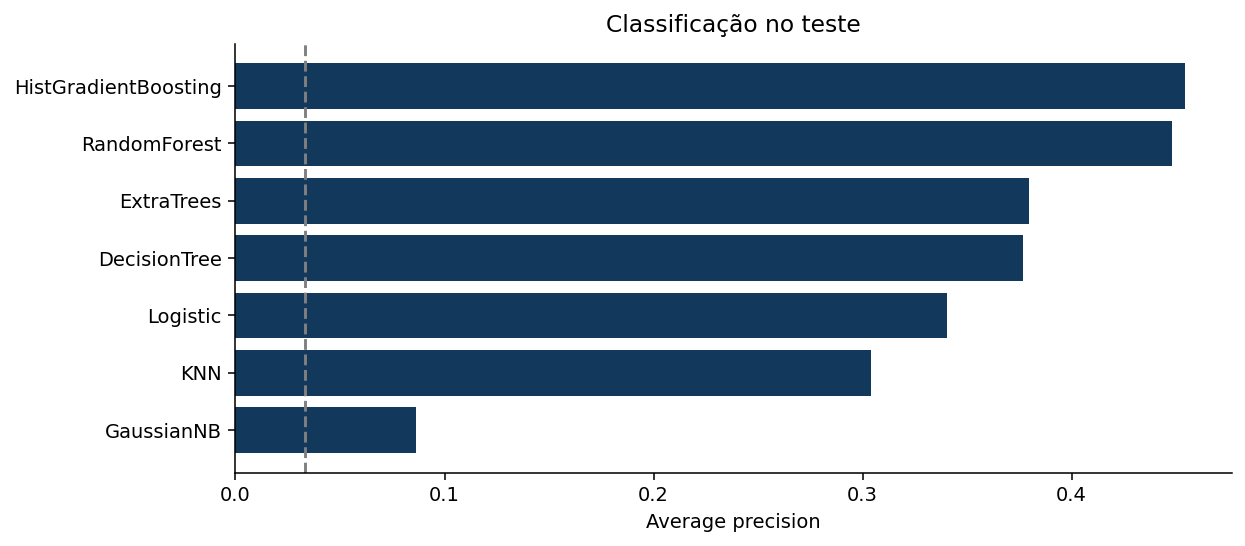

In [8]:
cm=read('classification_metrics.csv');cs=meta('classification_selection.json')
print('Campeão escolhido na validação:',cs['winner'])
display(cm[cm.split=='validation'].sort_values('captured_at_2pct',ascending=False))
display(cm[cm.split=='test'].sort_values('AP',ascending=False))
display(read('classification_baselines.csv'))
figure('classification_models')

## 9. Limiar e matriz de confusão
O limiar F1 foi escolhido na validação e aplicado ao score bruto. Ele produz uma decisão binária que serve ao diagnóstico. A fila econômica é outra decisão: ordena probabilidade calibrada × valor e preenche a capacidade diária. Ela não utiliza automaticamente o limiar F1.

Falso negativo é uma fraude fora da seleção. Falso positivo é uma transação legítima revisada. Revisar não é bloquear: o projeto representa triagem para investigação, com atraso e eficácia assumidos. Não demonstramos prevenção em tempo real ou recuperação garantida.

### Passo a passo: dois critérios produzem duas matrizes diferentes
O limiar F1 compara cada score com um valor fixo. A fila econômica escolhe os melhores scores monetários dentro de cada dia. Os grupos selecionados não precisam ser iguais.

A matriz exibida a seguir refere-se ao diagnóstico do limiar, não aos 333 casos da fila financeira. No teste, os números do diagnóstico são TN=14.995, FP=390, FN=299 e TP=231. Já a fila monetária principal contém 96 fraudes entre 333 análises.

**Por que 231 não é melhor que 96?** O primeiro número utiliza mais alertas e outra regra de seleção. A comparação financeira exige igual capacidade e considera o valor das fraudes. Misturar esses números levaria a uma conclusão errada.

**Resposta de defesa:** “O limiar ajuda a entender a classificação. Nossa decisão operacional principal é um ranking diário com capacidade fixa.”

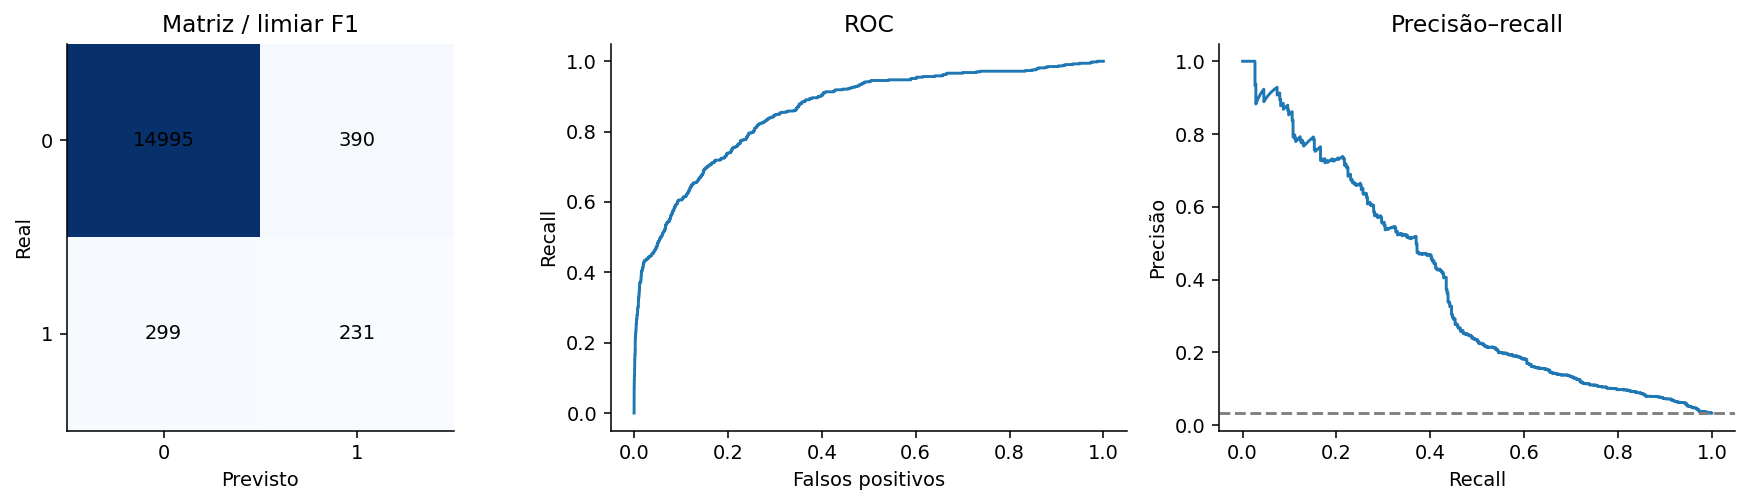

,Unnamed: 0,pred0,pred1
0,real0,14995,390
1,real1,299,231


In [9]:
figure('classification_diagnostics')
display(read('confusion_matrix.csv'))

## 10. Probabilidade calibrada e valor esperado
Platt ajusta uma regressão logística entre logit do score bruto e o rótulo no bloco de calibração. O modelo preditivo não é reajustado com os rótulos desse bloco. Avaliamos Brier bruto e calibrado no teste.

Multiplicar uma probabilidade por um valor conhecido produz uma estimativa de exposição esperada se a probabilidade for adequada. A calibração pode ser imperfeita, especialmente em subgrupos e em períodos futuros. Ser monotônica preserva a ordem de probabilidade isolada, mas pode mudar a ordem de probabilidade × valor.

### Passo a passo: probabilidade não é certeza
Dizer “probabilidade de 20%” significa que, em conjuntos comparáveis com esse risco, esperamos algo próximo de 20 fraudes a cada 100 transações se o modelo estiver bem calibrado. Não sabemos quais serão elas.

**Discriminação** é ordenar os casos; **calibração** é aproximar as probabilidades das frequências observadas. Um modelo pode ordenar bem e ser excessivamente confiante.

Platt aprende uma transformação usando um bloco separado. Como `logit(p)=log(p/(1−p))`, os scores são limitados antes da transformação para evitar logaritmos de zero. A transformação não consulta os rótulos de teste.

**Leia o gráfico:** distâncias da diagonal indicam discrepâncias entre risco previsto e frequência. Grupos com poucos exemplos têm estimativas instáveis. Brier menor no período avaliado não garante calibração perfeita em todos os subgrupos.

**Importância por permutação:** embaralha uma entrada e mede a piora. É uma associação com a previsão, não prova de causa. Variáveis correlacionadas podem dividir ou esconder importância.

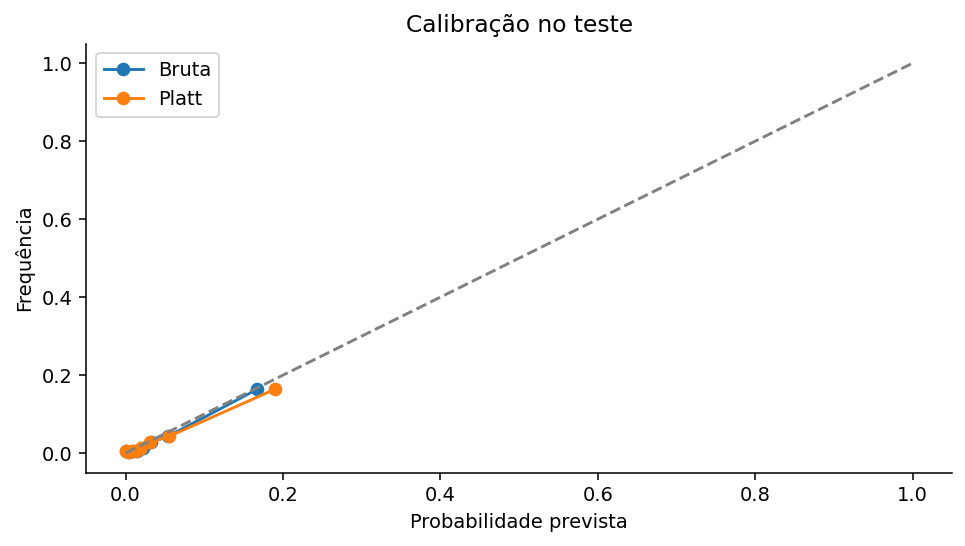

,model,Brier,calibrated_Brier,AP,ROC_AUC
11,ExtraTrees,0.0259,0.0257,0.3794,0.8593


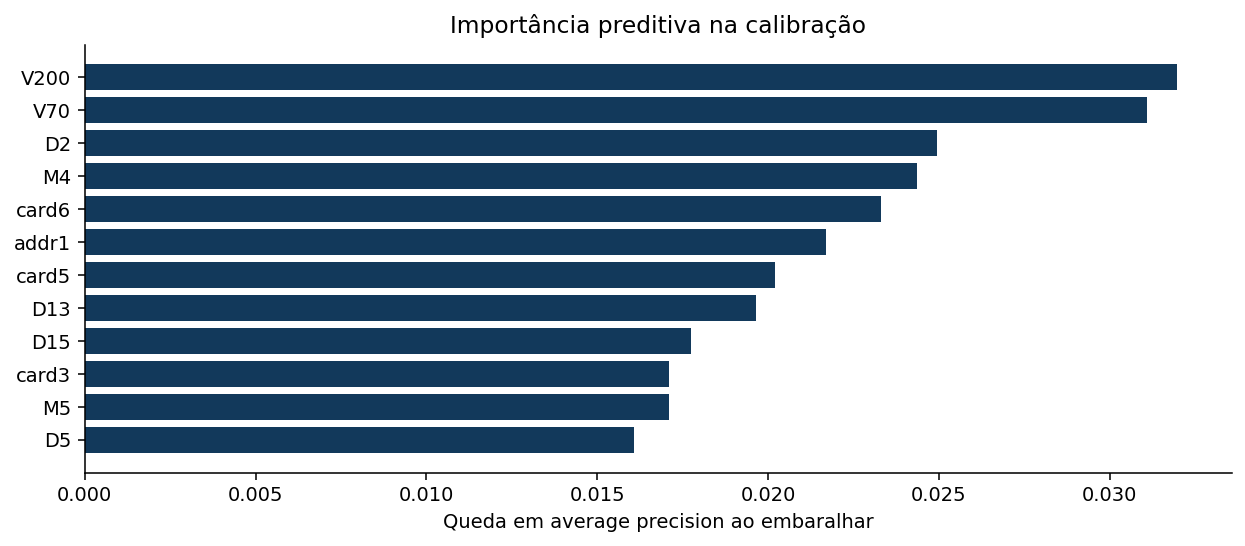

In [10]:
figure('calibration')
display(cm[(cm.model==cs['winner'])&(cm.split=='test')][['model','Brier','calibrated_Brier','AP','ROC_AUC']])
figure('importance')

## 11. Regressão de exposição monetária
Definimos `exposure = TransactionAmt × isFraud`: zero para transações legítimas, valor da transação para fraudes rotuladas. Esse é um alvo contínuo derivado, em moeda, e não o prejuízo líquido observado pela empresa. Ele reformula o mesmo risco da classificação; não representa um fenômeno independente.

O fato de o valor conhecido aparecer em X não revela o rótulo futuro. O modelo tenta aprender quanto dessa exposição estará associado a fraude. Não fornecemos `isFraud` ou `exposure` como entradas.

A distribuição tem muitos zeros e cauda pesada. MAE tende a favorecer previsões próximas de zero, enquanto erro quadrático procura a média condicional. Selecionamos por MSE de validação, alinhado a uma média esperada, mas avaliamos também MAE, RMSE e R². Um R² baixo ou negativo não invalida uma política de ranking; tampouco deve ser escondido.

### Passo a passo: por que uma regressão neste problema?
Se uma transação legítima vale US$ 500, seu alvo de exposição rotulada é 0. Se uma fraude vale US$ 500, o alvo é 500. No momento de prever, o rótulo ainda é desconhecido.

Como o montante A é conhecido, a média condicional ideal desse alvo é `E[A × Y | X] = A × P(Y=1 | X)` quando A está contido em X. Isso explica a ligação entre regressão direta e probabilidade vezes valor. Na prática, estimadores, perdas e erros de calibração produzem rankings diferentes.

**MAE** é o erro absoluto médio, em dólares. **MSE** é a média dos erros ao quadrado, em dólares². **RMSE** é a raiz do MSE, volta à unidade monetária e dá mais peso aos erros grandes. **R² = 1 − SSE/SST** compara o erro quadrático com uma referência constante baseada na média do próprio conjunto avaliado; pode ser negativo.

O R² do regressor escolhido fica próximo de 0,25 no teste. Não escondemos esse resultado nem buscamos um R² artificialmente alto. A utilidade de priorização é medida separadamente, com o orçamento fixo.

**Resposta de defesa:** “Não estamos prevendo o montante, que já é conhecido. Estamos estimando quanto desse montante está associado ao evento fraude.”

Campeão de regressão escolhido por MSE na validação: RandomForest


,model,split,MAE,MSE,RMSE,R2
15,RandomForest,validation,9.9765,3710.0840,60.9105,0.1446
18,ExtraTrees,validation,9.8647,3756.2300,61.2881,0.1339
21,HistGradientBoosting,validation,9.7499,3769.3422,61.3950,0.1309
12,DecisionTree,validation,10.1304,3786.7654,61.5367,0.1269
0,Linear,validation,12.0230,4112.4667,64.1285,0.0518
3,Ridge,validation,11.9083,4113.2835,64.1349,0.0516
6,Lasso,validation,11.4758,4130.6665,64.2703,0.0476
9,ElasticNet,validation,11.4622,4135.3937,64.3070,0.0465


,model,split,MAE,MSE,RMSE,R2
23,HistGradientBoosting,test,8.0631,1574.0177,39.6739,0.2574
17,RandomForest,test,8.2951,1597.1017,39.9638,0.2465
20,ExtraTrees,test,8.6650,1772.3408,42.0992,0.1638
14,DecisionTree,test,8.2520,1790.8583,42.3185,0.1551
8,Lasso,test,10.8736,2052.2305,45.3016,0.0318
5,Ridge,test,11.1933,2053.5406,45.3160,0.0312
11,ElasticNet,test,10.8287,2054.3298,45.3247,0.0308
2,Linear,test,11.2286,2056.4582,45.3482,0.0298


,model,MAE,MSE,RMSE,R2
0,Zero,4.9545,2144.1344,46.3048,-1.1581e-02
1,TrainingMean,9.4997,2119.5944,46.0391,-3.4622e-06
2,GlobalRateAmount,9.2036,2091.6180,45.7342,1.3196e-02


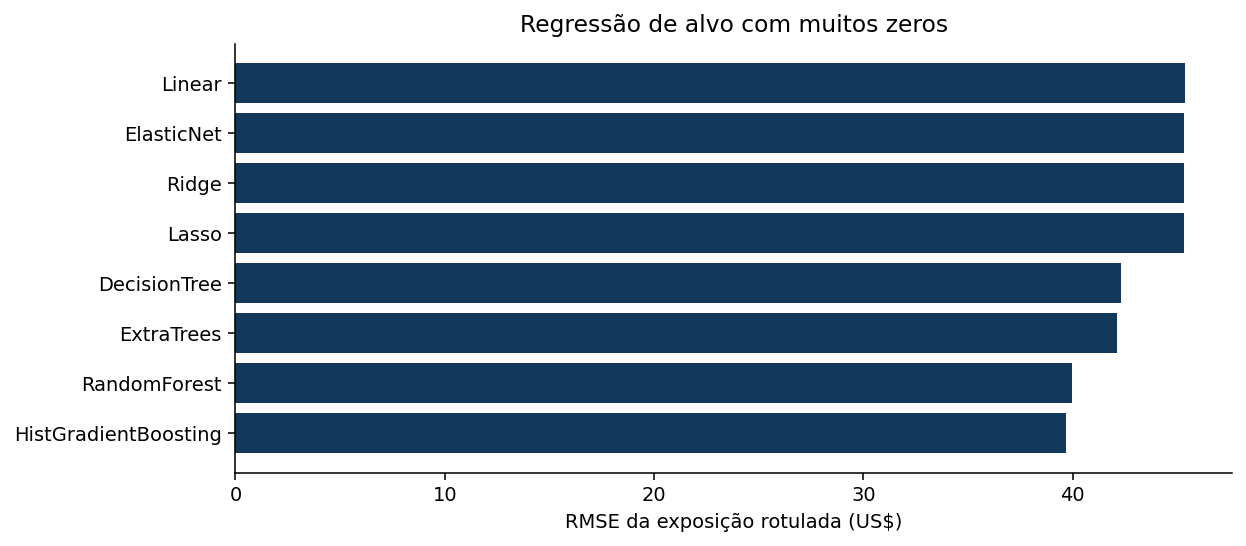

In [11]:
rm=read('regression_metrics.csv');rs=meta('regression_selection.json')
print('Campeão de regressão escolhido por MSE na validação:',rs['winner'])
display(rm[rm.split=='validation'].sort_values('MSE'))
display(rm[rm.split=='test'].sort_values('MSE'))
display(read('regression_baselines.csv'))
figure('regression_models')

## 12. Agrupamento de transações e PCA
Agrupamos duas mil transações sorteadas apenas do treino, sem usar rótulos. Nove indicadores numéricos passam por mediana, log1p após truncamento inferior em zero, e padronização. Essa transformação reduz o domínio de caudas. O truncamento é uma escolha para essa análise exploratória e pode perder informação de sinais negativos.

Comparamos k de 2 a 6 em K-means e hierárquico e quatro eps de DBSCAN. Silhouette favorece separação, Davies–Bouldin favorece grupos compactos e distintos. DBSCAN calcula métricas apenas nos pontos não marcados como ruído, exigindo mostrar a fração excluída. Um único grupo não tem silhouette definido.

PCA maximiza variância e produz uma projeção linear. Os coeficientes das componentes não são efeitos causais. A taxa de fraude dos grupos é calculada somente depois do agrupamento como descrição, não como critério usado para construí-los.

### Passo a passo: o que os grupos realmente mostram?
**K-means:** procura centros que reduzam a distância quadrática dentro dos grupos. **Hierárquico:** constrói uniões sucessivas; o corte define quantos grupos apresentar. **DBSCAN:** procura regiões densas e pode deixar pontos como ruído. Ruído não significa fraude.

**Silhouette:** combina proximidade ao próprio grupo e separação dos demais; maior costuma ser melhor. **Davies–Bouldin:** relaciona dispersão e separação; menor costuma ser melhor. Compare também tamanho dos grupos e fração de ruído, não apenas um índice.

**PCA:** cria novas coordenadas que concentram variância. Se duas componentes não preservam toda a variância, o gráfico bidimensional omite parte da estrutura. “Variância explicada” no PCA não é o R² da regressão nem porcentagem de fraudes detectadas.

**ARI de estabilidade:** compara agrupamentos de sementes distintas, descontando concordância casual. Estabilidade ajuda a avaliar repetibilidade, mas não demonstra significado de negócio.

**Resposta de defesa:** “Usamos agrupamento para explorar perfis sem fornecer o rótulo. Consultamos a taxa de fraude depois, como descrição. Não chamamos os grupos de tipos comprovados de fraude.”

,method,config,silhouette,DB,noise
0,KMeans,k=2,0.5521,0.8327,0.0000
1,KMeans,k=3,0.2870,1.3066,0.0000
2,KMeans,k=4,0.3008,1.2221,0.0000
3,KMeans,k=5,0.2359,1.2608,0.0000
4,KMeans,k=6,0.2317,1.4725,0.0000
5,Hierarchical,k=2,0.5800,0.7563,0.0000
6,Hierarchical,k=3,0.2360,1.3829,0.0000
7,Hierarchical,k=4,0.2568,1.2876,0.0000
8,Hierarchical,k=5,0.1851,1.5120,0.0000
9,Hierarchical,k=6,0.1975,1.4479,0.0000


,cluster,n,fraud_rate,amount
0,0,1880,0.0452,136.3493
1,1,120,0.0667,100.7212


,seed,ARI
0,7,1.0
1,21,1.0
2,84,1.0


,component,variance,cumulative
0,1,0.4088,0.4088
1,2,0.1566,0.5653
2,3,0.1192,0.6845
3,4,0.1083,0.7929
4,5,0.0974,0.8902
5,6,0.0475,0.9378
6,7,0.0424,0.9801
7,8,0.0148,0.9950
8,9,0.0050,1.0000


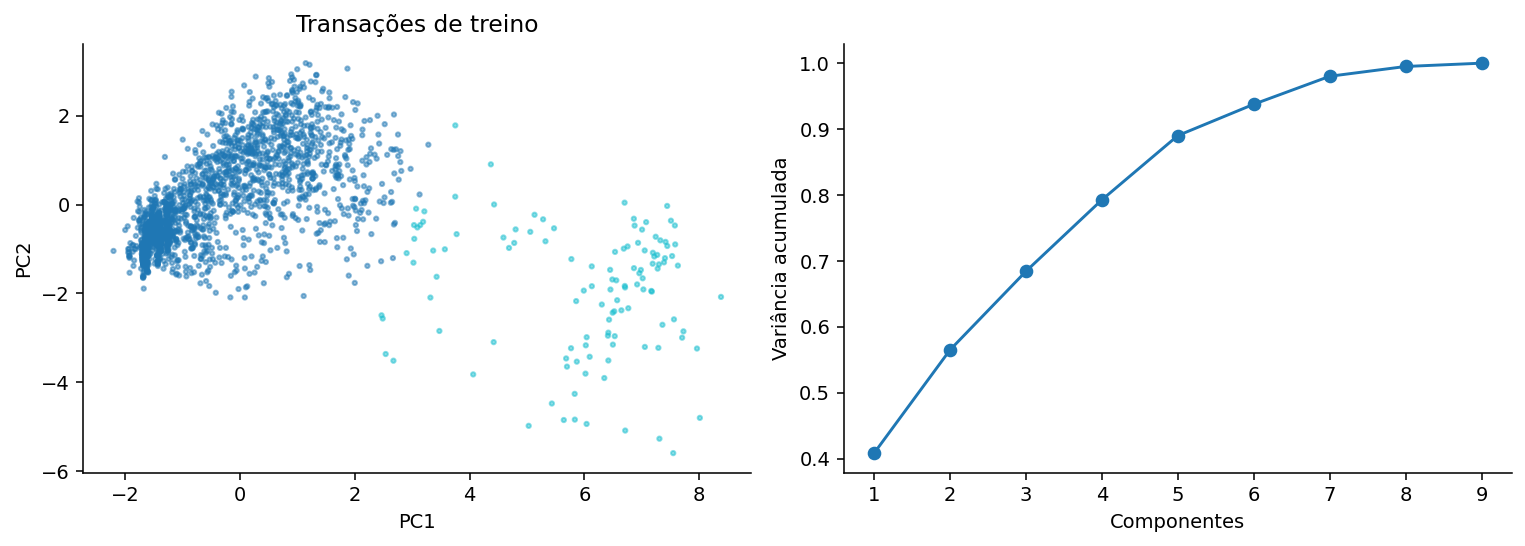

In [12]:
display(read('clustering_metrics.csv'))
display(read('cluster_profiles.csv'))
display(read('cluster_stability.csv'))
display(read('pca_variance.csv'))
figure('clusters_pca')

## 13. Políticas operacionais comparáveis
Todas as políticas revisam `ceil(capacidade × transações do dia)` casos, mesmo que os scores sejam baixos. Empates são resolvidos por linha de origem, sem olhar o rótulo. Isso mede ganho de priorização com orçamento fixo, não a capacidade ótima da empresa.

| Política | Score usado |
|---|---|
| Random | Sorteio reprodutível independente do rótulo |
| LargestAmount | Valor da transação |
| ProductRateAmount | Taxa histórica suavizada do produto × valor |
| ML_Probability | Probabilidade calibrada |
| ML_ExpectedAmount | Probabilidade calibrada × valor; política principal |
| RegressionExposure | Previsão do regressor de exposição |

A referência é a melhor das três regras simples na validação. Depois do teste, mantemos essa referência mesmo se outra regra simples se destacar. Analisar montantes identifica o que está em jogo; não é necessário inventar o custo de aquisição ou margem de um produto.

### Passo a passo: construir uma comparação justa
1. Separe as transações por dia relativo.
2. Calcule a capacidade de cada dia com arredondamento para cima.
3. Ordene cada política usando somente informação permitida.
4. Selecione exatamente essa quantidade, inclusive quando os scores forem baixos.
5. Só depois consulte rótulos e calcule quantidades e montantes.

A ordem é decisiva: usar o rótulo para desempatar seria vazamento. `source_row` fornece um desempate determinístico independente do rótulo.

Em 28 dias, a capacidade de 2% resulta em 333 análises, acima de `0,02 × 15.915 = 318,3` porque arredondamos separadamente cada dia. Não apresentamos 333 como 2% exatos do total.

**Por que maiores valores é uma referência forte?** Ela já coloca dinheiro no centro da seleção. Superá-la permite atribuir parte do resultado à informação de risco, além da informação de valor.

Referência congelada: LargestAmount


,policy,reviewed,fraud_reviewed,legitimate_reviewed,precision,recall,labeled_amount_captured,amount_recall,review_cost,net_benefit,total_loss,no_action_loss
0,Random,342,12,330,0.0351,0.0185,632.298,0.0054,684.0,-178.1616,116727.0486,116548.887
1,LargestAmount,342,37,305,0.1082,0.0570,39828.460,0.3417,684.0,31178.7680,85370.1190,116548.887
2,ProductRateAmount,342,39,303,0.1140,0.0601,37560.792,0.3223,684.0,29364.6336,87184.2534,116548.887


,policy,capacity,scenario,cost,efficacy,fp_penalty,reviewed,fraud_reviewed,legitimate_reviewed,precision,recall,labeled_amount_captured,amount_recall,review_cost,net_benefit,total_loss,no_action_loss
44,RegressionExposure,0.02,central,2.0,0.8,0.0,333,105,228,0.3153,0.1981,36919.505,0.4682,666.0,28869.6040,49981.6510,78851.255
40,ML_ExpectedAmount,0.02,central,2.0,0.8,0.0,333,96,237,0.2883,0.1811,35111.123,0.4453,666.0,27422.8984,51428.3566,78851.255
36,ML_Probability,0.02,central,2.0,0.8,0.0,333,168,165,0.5045,0.3170,18896.144,0.2396,666.0,14450.9152,64400.3398,78851.255
28,LargestAmount,0.02,central,2.0,0.8,0.0,333,17,316,0.0511,0.0321,14670.000,0.1860,666.0,11070.0000,67781.2550,78851.255
32,ProductRateAmount,0.02,central,2.0,0.8,0.0,333,16,317,0.0480,0.0302,10290.014,0.1305,666.0,7566.0112,71285.2438,78851.255
24,Random,0.02,central,2.0,0.8,0.0,333,11,322,0.0330,0.0208,881.026,0.0112,666.0,38.8208,78812.4342,78851.255


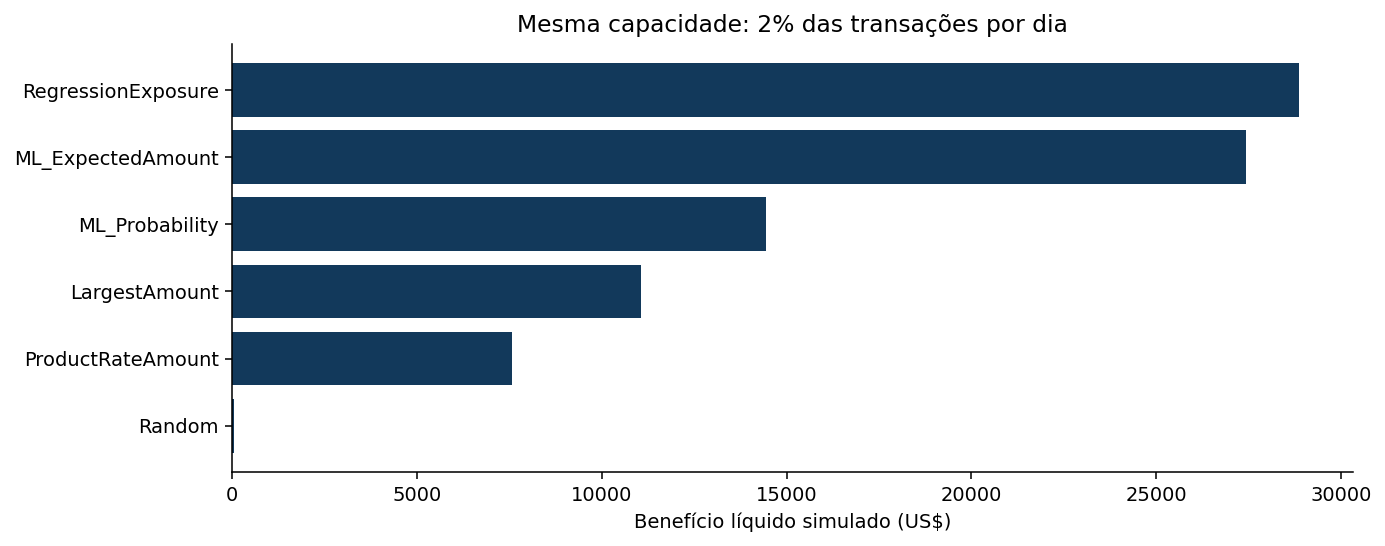

In [13]:
fin=read('financial_policies.csv');bsel=meta('baseline_selection.json')
print('Referência congelada:',bsel['comparator'])
display(pd.DataFrame(bsel['validation']))
display(fin[(fin.scenario=='central')&(fin.capacity==.02)].sort_values('net_benefit',ascending=False))
figure('financial_comparison')

## 14. O que é observado e o que é assumido
**Observado no dataset:** valor da transação, rótulo, fila selecionada e soma do valor rotulado revisado. Não observamos o efeito de investigar uma transação que não teria sido investigada na operação real.

**Hipóteses centrais:** custo de US$ 2 por investigação, eficácia de 80% sobre o valor fraudulento identificado e penalidade adicional zero por revisão legítima. “Eficácia” agrega a possibilidade de evitar ou recuperar uma parte da exposição. Não é uma taxa medida nessa base.

Para cada política:

`benefício líquido simulado = eficácia × valor fraudulento identificado − custo × análises − penalidade × revisões legítimas`.

`perda total simulada = valor fraudulento total − benefício líquido simulado`.

A diferença entre política e referência mede benefício incremental. As duas têm o mesmo número de análises, logo custos fixos por análise se cancelam na diferença quando não há penalidade adicional. O resultado não inclui implantação, manutenção, atrasos, qualidade da investigação ou efeito sobre clientes.

### Passo a passo: refazer a conta que sustenta o trabalho
No teste, a exposição fraudulenta rotulada total é US$ 78.851,255. A fila principal identifica US$ 35.111,123; a regra de maiores valores identifica US$ 14.670. Ambas usam 333 análises.

Com eficácia de 80% e custo de US$ 2 por análise:

- Modelo: `0,8 × 35.111,123 − 2 × 333 = US$ 27.422,8984` de benefício líquido simulado.
- Referência: `0,8 × 14.670 − 2 × 333 = US$ 11.070`.
- Contribuição incremental: `27.422,8984 − 11.070 = US$ 16.352,8984`.
- Perda simulada da referência: `78.851,255 − 11.070 = US$ 67.781,255`.
- Redução relativa dessa perda: `16.352,8984 / 67.781,255 ≈ 24,13%`.

O denominador de 24,13% é a perda simulada da referência. Não é o valor total de todas as transações, não é o percentual de fraudes encontradas e não é retorno sobre investimento de implantação.

**Resposta pronta:** “Na amostra de teste, com a mesma capacidade, nosso ranking identificou mais valor de fraude. Sob eficácia de 80% e custo de dois dólares por análise, isso equivale a cerca de 16,35 mil dólares adicionais e 24,13% menos perda que a regra de maiores valores.”

Valor rotulado identificado: US$ 35,111.12
Benefício incremental simulado: US$ 16,352.90
Redução da perda da referência: 24.13%
Precisão da fila: 28.8% | cobertura monetária: 44.5%


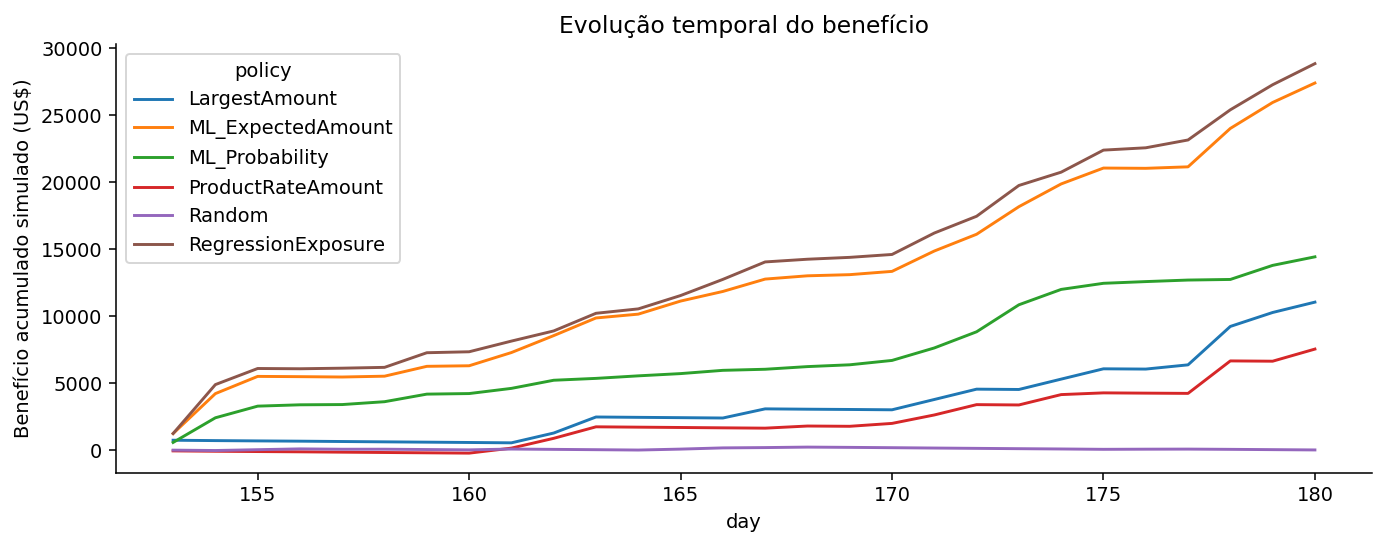

In [14]:
central=fin[(fin.scenario=='central')&(fin.capacity==.02)].set_index('policy')
main=central.loc['ML_ExpectedAmount'];baseline=central.loc[bsel['comparator']]
delta=main.net_benefit-baseline.net_benefit
print(f'Valor rotulado identificado: US$ {main.labeled_amount_captured:,.2f}')
print(f'Benefício incremental simulado: US$ {delta:,.2f}')
print(f'Redução da perda da referência: {100*delta/baseline.total_loss:.2f}%')
print(f'Precisão da fila: {100*main.precision:.1f}% | cobertura monetária: {100*main.amount_recall:.1f}%')
figure('financial_timeline')

## 15. Capacidade, custos e eficácia
Testamos capacidades de 1%, 2%, 5% e 10% por dia. Maior capacidade pode capturar mais fraude, mas exige mais trabalho e pode aumentar falsos positivos. A capacidade principal permanece 2%, definida antes do teste.

Cenários: central; eficácia reduzida a 50%; custo de US$ 10 por investigação; e penalidade ilustrativa adicional de US$ 10 por transação legítima revisada. Não escolhemos o cenário mais favorável para apresentar como principal. Esses custos não são parâmetros fornecidos pela Vesta.

Comparar apenas com nenhuma análise produziria uma impressão exagerada da contribuição de ML. Exibimos também quanto as regras simples já conseguiriam identificar.

### Passo a passo: o que faz o ganho mudar?
Com a mesma quantidade de análises e sem penalidade adicional, o custo unitário se cancela na diferença entre políticas. Aumentar esse custo reduz o benefício absoluto de ambas, mas não muda o benefício incremental em dólares. A redução percentual pode mudar porque o denominador muda.

A eficácia multiplica a diferença de valor capturado. Se for zero, não existe benefício monetário da captura neste modelo. Custos adicionais de implantação consumiriam parte do ganho: o estudo não os mediu.

Uma penalidade para revisão legítima não se cancela quando as filas têm quantidades diferentes de legítimas. Essa hipótese representa atrito ou trabalho adicional e precisa ser apresentada como cenário.

**Não anualize automaticamente:** os 28 dias não provam estabilidade por um ano, nem a amostra representa o volume completo de uma empresa. Cenários servem para entender dependência das hipóteses, não para escolher a história mais favorável.

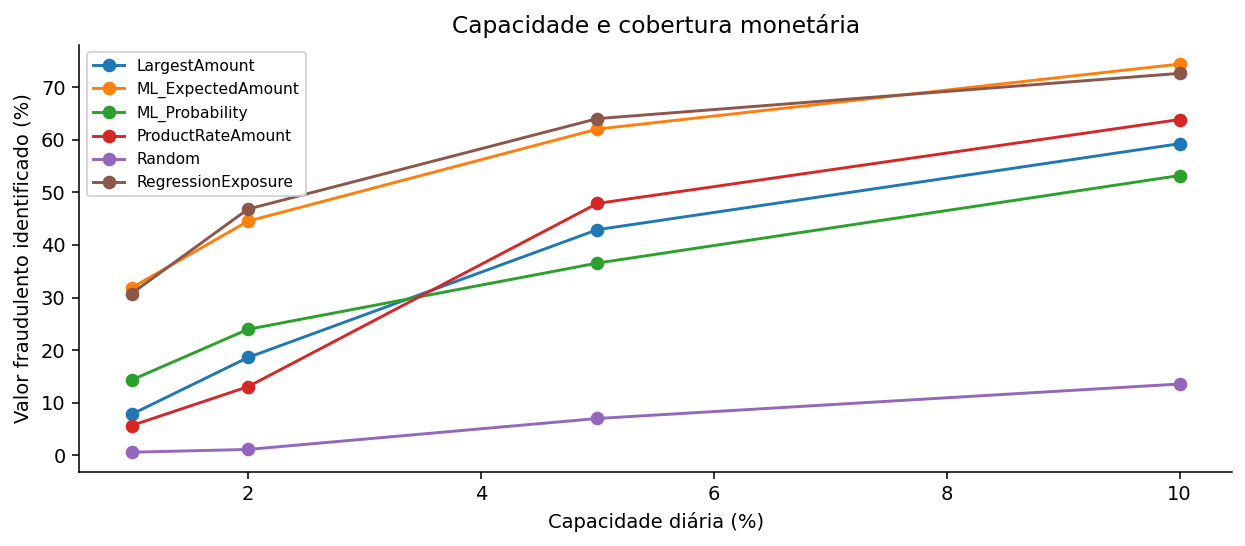

,cenario,beneficio_incremental,reducao_perda_percentual,beneficio_modelo_vs_nao_agir
0,central,16352.8984,24.1260,27422.8984
1,fp_penalty,17142.8984,24.1649,25052.8984
2,high_cost,16352.8984,23.2136,24758.8984
3,low_efficacy,10220.5615,14.1594,16889.5615


In [15]:
figure('capacity')
sensitivity=[]
for scenario,g in fin[fin.capacity==.02].groupby('scenario'):
    q=g.set_index('policy');a=q.loc['ML_ExpectedAmount'];b=q.loc[bsel['comparator']]
    sensitivity.append({'cenario':scenario,'beneficio_incremental':a.net_benefit-b.net_benefit,
                        'reducao_perda_percentual':100*(a.net_benefit-b.net_benefit)/b.total_loss,
                        'beneficio_modelo_vs_nao_agir':a.net_benefit})
display(pd.DataFrame(sensitivity))

## 16. Incerteza, estabilidade e verificação
O bootstrap pareado reamostra blocos circulares de sete dias com todas as transações de cada dia juntas. São cinco mil réplicas. Isso preserva parte da dependência temporal, mas 28 dias fornecem poucos blocos independentes. O intervalo é exploratório e não substitui avaliação em outros períodos ou um piloto causal.

As verificações exigem separação de dias, ausência do rótulo nas entradas, identidade da exposição, previsões finitas e igualdade exata dos orçamentos por política e dia. Uma verificação embaralha o rótulo depois dos scores e confirma que as decisões não mudam: a política seleciona sem conhecer a verdade do teste.

### Passo a passo: entender o intervalo de incerteza
A unidade de reamostragem é um bloco de dias, não uma transação independente. Reamostrar transações isoladas ignoraria choques e dependência temporal compartilhados.

**Pareado** significa que, em cada réplica, modelo e referência recebem os mesmos dias. Calculamos a diferença nas duas políticas dentro da mesma réplica. Isso evita comparar períodos distintos por acidente.

O intervalo exploratório principal é aproximadamente US$ 11,87 mil a US$ 21,33 mil. Ele resume a variação da diferença no procedimento de reamostragem, sob os custos e a eficácia escolhidos. Não é uma garantia de que 95% dos ganhos futuros estarão aí, nem incorpora automaticamente erros nas hipóteses econômicas.

Com apenas quatro semanas de teste, a diversidade temporal é limitada. Um intervalo inteiramente positivo reforça a evidência nesse recorte, sem provar efeito causal.

**Contra logística:** o ganho adicional do campeão é cerca de US$ 4.785,62, ou 8,51% de redução da perda simulada da logística. Esse diagnóstico posterior mostra que um modelo simples já entrega parte importante do resultado; não redefine o campeão.

In [16]:
display(pd.DataFrame([meta('financial_bootstrap.json')]))
checks=read('verification.csv')
print('Verificações aprovadas:',int(checks.passed.sum()),'de',len(checks))
display(checks.head(14))

,main_policy,comparator,capacity,incremental_benefit,ci95_low,ci95_high,days,block_days,note
0,ML_ExpectedAmount,LargestAmount,0.02,16352.8984,11865.4163,21326.9899,28,7,Exploratory paired circular bootstrap; few ind...


Verificações aprovadas: 125 de 125


,check,passed
0,Unique source rows,True
1,Targets excluded,True
2,Temporal train/validation,True
3,Temporal validation/calibration,True
4,Temporal calibration/test,True
5,Class target valid,True
6,Monetary proxy identity,True
7,Finite predictions,True
8,Equal review budgets 0.01,True
9,Capacity 0.01 day153,True


### Diagnóstico adicional contra um modelo simples de risco
A referência principal continua sendo a regra escolhida antes do teste. Para não atribuir todo o benefício a uma arquitetura complexa, também mostramos todos os classificadores sob o mesmo orçamento. Uma regressão logística simples já identifica valor relevante; a contribuição adicional do campeão deve ser avaliada contra ela. Este diagnóstico não muda o campeão depois de olhar o teste.

In [17]:
display(read('financial_all_classifiers.csv').sort_values('net_benefit',ascending=False))
display(pd.DataFrame([meta('logistic_comparator_bootstrap.json')]))

,model,reviewed,fraud_reviewed,legitimate_reviewed,precision,recall,labeled_amount_captured,amount_recall,review_cost,net_benefit,total_loss,no_action_loss
2,RandomForest,333,107,226,0.3213,0.2019,39280.346,0.4982,666.0,30758.2768,48092.9782,78851.255
4,HistGradientBoosting,333,114,219,0.3423,0.2151,38044.572,0.4825,666.0,29769.6576,49081.5974,78851.255
3,ExtraTrees,333,96,237,0.2883,0.1811,35111.123,0.4453,666.0,27422.8984,51428.3566,78851.255
1,DecisionTree,333,96,237,0.2883,0.1811,33041.033,0.4190,666.0,25766.8264,53084.4286,78851.255
0,Logistic,333,72,261,0.2162,0.1358,29129.098,0.3694,666.0,22637.2784,56213.9766,78851.255
6,GaussianNB,333,35,298,0.1051,0.0660,21676.879,0.2749,666.0,16675.5032,62175.7518,78851.255
5,KNN,333,25,308,0.0751,0.0472,20985.000,0.2661,666.0,16122.0000,62729.2550,78851.255


,candidate,reference,incremental_benefit,ci95_low,ci95_high,note
0,ExtraTrees,Logistic,4785.62,2803.7722,6760.3689,Additional diagnostic after primary evaluation...


## 17. Limitações e ética
O espelho e as features anonimizadas limitam a auditoria de como cada atributo foi calculado. A partição temporal não garante independência por cliente. O orçamento se refere à amostra sistemática, e o teste cobre apenas 28 dias. O custo e a eficácia de investigação não são observados. Uma investigação pode ocorrer tarde demais para impedir uma perda, e o rótulo histórico pode refletir processos operacionais existentes.

O projeto não autoriza bloqueio automático de cartões. Transações legítimas revisadas podem causar atrito e tratamento desigual. Não tentamos reidentificar pessoas. Dados públicos e anonimizados não substituem uma análise de finalidade, proteção de dados, LGPD e governança numa implantação real. Não declaramos conformidade jurídica a partir deste estudo.

A classificação e a regressão reformulam o mesmo risco. Clusters são exploratórios. Não atribuímos economia a segmentação ou explicações sem avaliar uma ação. O benefício simulado deve ser descontado de implantação e manutenção antes de discutir retorno de investimento.

### Passo a passo: responder limitações sem desvalorizar o estudo
Use a sequência **limite → consequência → próxima verificação**. Exemplo: “Temos apenas 28 dias de teste; isso limita a estabilidade temporal; repetiríamos em outros períodos antes de implantação”.

Outros exemplos: atributos mascarados limitam a tradução causal; custos assumidos exigem sensibilidade; falta de identificador confiável impede validar clientes inéditos; rótulos históricos podem refletir o processo de confirmação de fraude.

O caráter acadêmico permite estudar essas decisões com hipóteses explícitas. Uma boa defesa sabe delimitar a evidência, sem transformar cada limitação em uma afirmação de que o modelo não serve.

## 18. Insights e decisão de implantação
A análise deve separar três coisas: reconhecer padrões de fraude, ordenar casos pelo valor em risco e transformar a fila em uma intervenção eficaz. Um classificador com bom F1 pode não maximizar o valor capturado. Revisar somente os maiores valores já é um baseline relevante.

Uma vantagem grande no teste é uma razão para investigar um piloto, não prova de lucro futuro. O piloto precisaria medir capacidade, tempo de resposta, eficácia, custo, atrito de clientes e estabilidade temporal. Os resultados abaixo são calculados dos arquivos, sem números escolhidos para produzir uma narrativa favorável.

### Passo a passo: interpretar o conjunto, não apenas a melhor tabela
Ao apresentar os resultados, mantenha quatro perguntas: o modelo prevê melhor? a fila seleciona melhor? a diferença tem relevância financeira sob as hipóteses? o desenho permite sustentar essa conclusão?

Não compare diretamente R² da regressão, AP da classificação e silhouette do agrupamento. Medem tarefas diferentes. O vínculo entre as frentes é o problema de negócio e a análise dos dados, não uma escala única de desempenho.

**Frase central:** “O estudo mostra como converter uma previsão de risco em uma política de priorização e medir sua contribuição incremental em condições comparáveis.”

In [18]:
print('Campeão:',cs['winner'])
print('Referência:',bsel['comparator'])
print('Valor total de fraudes rotuladas no teste:',d.loc[d.split=='test','exposure'].sum())
print('Valor identificado pelo modelo:',main.labeled_amount_captured)
print('Valor identificado pela referência:',baseline.labeled_amount_captured)
print('Diferença financeira central:',delta)

Campeão: ExtraTrees
Referência: LargestAmount
Valor total de fraudes rotuladas no teste: 78851.255
Valor identificado pelo modelo: 35111.123
Valor identificado pela referência: 14670.0
Diferença financeira central: 16352.898399999998


## 19. Comparação com o projeto M5
Os projetos têm dados, horizontes, unidades e políticas diferentes. Somar dólares ou comparar seus valores absolutos não mostra qual modelo é “melhor”. O M5 avalia estoque sob custos e recuperação assumidos. Fraude avalia triagem com valores rotulados conhecidos, mas eficácia e custo assumidos.

A comparação considera redução de custo frente a uma referência simples forte, intervalo de incerteza, naturalidade das tarefas, interpretabilidade, dependência de premissas e clareza da defesa. O documento comparativo apresenta essa leitura sem tratar os projetos como dois algoritmos testados no mesmo conjunto.

### Passo a passo: explicar por que escolhemos fraude
O M5 responde a uma decisão de estoque e mostrou pequeno ganho incremental sobre uma referência já forte. Fraude apresentou uma diferença financeira mais clara dentro do próprio experimento. Isso favorece a narrativa deste trabalho acadêmico.

Não concluímos que um setor é sempre superior ao outro ou que um algoritmo é universalmente melhor. As bases, alvos, períodos e hipóteses são distintos. A comparação relevante é a força da evidência e a clareza da aplicação de cada projeto.

In [19]:
comparison_path=ROOT.parent/'Comparacao'/'comparison.csv'
if comparison_path.exists():display(pd.read_csv(comparison_path))
else:print('Os resultados comparativos serão gerados após fechar a avaliação.')

,projeto,referencia,reducao_custo_percentual,beneficio_incremental_USD,intervalo95_inferior,intervalo95_superior,periodo,evidencia
0,M5 / estoque,Média móvel calibrada,0.8664,56.6746,-32.3524,141.1177,20 semanas,Intervalo inclui zero
1,IEEE-CIS / fraude,Maiores transações / mesmo orçamento,24.1260,16352.8984,11865.4163,21326.9899,28 dias,Intervalo exploratório positivo


## 20. Demonstração executável em dois minutos
Mostre uma linha de transação, as entradas sem rótulo, o ajuste de um modelo e a fila com orçamento fixo. A célula seguinte treina de verdade um modelo logístico simples; ela não substitui o campeão do estudo nem altera a seleção. O ajuste completo fica disponível via script e não depende de rede depois do download.

### Passo a passo: usar a demonstração na apresentação
Antes de executar, diga quais dados a célula lê, qual transformação realiza e qual resultado espera observar. Depois, explique uma linha da saída. Executar sem interpretar não demonstra domínio.

A demonstração pequena é didática; não substitui o treinamento congelado do campeão. Para reproduzir o estudo completo, use a configuração e os scripts da seção de reprodutibilidade. Executar o modo de leitura consulta resultados já salvos.

Se o professor alterar uma hipótese econômica, mude a conta ou a simulação, não retreine o classificador sem necessidade. Se alterar a capacidade, é preciso reconstruir as seleções diárias; não basta multiplicar o benefício por dois.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
# Aprende transformações e modelo apenas em dados anteriores ao teste.
tr=budget_sample(d[d.split=='train'])
test=d[d.split=='test']
demo=Pipeline([('pre',preprocess()),('model',LogisticRegression(C=.1,max_iter=600))])
demo.fit(tr[NUM+CAT],tr.isFraud)
prob=demo.predict_proba(test[NUM+CAT])[:,1]
mask=review_mask(test,prob*test.TransactionAmt,.02)
display(pd.DataFrame([financial(test,mask)]))
display(test[['source_row','day','TransactionAmt','isFraud']].assign(
    probabilidade=prob,score_valor=prob*test.TransactionAmt,revisar=mask).head(10))
assert 'isFraud' not in NUM+CAT

/Users/joaopedrocastro/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/joaopedrocastro/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/joaopedrocastro/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/joaopedrocastro/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/joaopedrocastro/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  g

,reviewed,fraud_reviewed,legitimate_reviewed,precision,recall,labeled_amount_captured,amount_recall,review_cost,net_benefit,total_loss,no_action_loss
0,333,79,254,0.2372,0.1491,27576.184,0.3497,666.0,21394.9472,57456.3078,78851.255


,source_row,day,TransactionAmt,isFraud,probabilidade,score_valor,revisar
100618,508215,153,54.500,0,0.0146,0.7968,False
100619,508220,153,20.657,0,0.0385,0.7960,False
100620,508225,153,47.950,0,0.0002,0.0108,False
100621,508230,153,319.950,0,0.0179,5.7408,False
100622,508235,153,76.235,0,0.1098,8.3725,False
100623,508240,153,117.000,0,0.0085,0.9993,False
100624,508245,153,39.950,0,0.0028,0.1102,False
100625,508250,153,159.950,0,0.0009,0.1376,False
100626,508255,153,29.000,0,0.0159,0.4625,False
100627,508260,153,100.000,0,0.0790,7.9023,False


## 21. Perguntas prováveis do professor
### Base e problema
**O que é a base?** Transações reais de comércio eletrônico disponibilizadas por Vesta e IEEE-CIS, com rótulos históricos de fraude. Baixamos um espelho OpenML documentado e preservamos a origem.

**Por que não usar o arquivo direto do Kaggle?** O espelho é público e permite reproduzir o download. A fonte original e os direitos continuam os da competição; o arquivo não se torna de domínio público.

**Uma linha é um cliente?** Não, é uma transação. Não possuímos uma chave confiável que identifique clientes de forma completa.

**O que significa cada V ou C?** Muitas definições são ocultadas pelo provedor. Podemos explicar a família geral e o comportamento estatístico, mas não inventar uma interpretação específica.

**Por que 456 campos no espelho?** Há atributos de identidade com variantes de nomes. Lemos uma lista predefinida e auditamos o esquema recebido, sem assumir identidade perfeita com todas as versões da competição.

**Por que uma em cada cinco linhas?** Para limitar processamento sem selecionar pelo rótulo ou por resultado futuro. A amostra é sistemática e não representa automaticamente todo o fluxo de produção.

**Por que só 30 mil linhas para treinar?** É um orçamento comum a todos os algoritmos que permite comparação reproduzível. O teste usa todas as linhas de seu bloco da amostra. Mais dados é uma extensão possível, sem promessa de melhora.

**Por que não retirar valores altos?** O valor é parte do risco econômico. Apagar montantes extremos só por serem extremos poderia esconder o problema real.

### Metodologia
**Por que separar por tempo?** O uso real recebe transações futuras. Dividir aleatoriamente poderia misturar padrões posteriores no treino.

**O teste tem clientes inéditos?** Não sabemos. A avaliação mede um fluxo posterior; não comprova generalização para novos clientes.

**Onde poderia haver vazamento?** Em rótulos ou valores derivados entrando em X, agregações futuras, transformações ajustadas fora do treino e escolha retrospectiva de políticas. A origem de features ocultas também limita a auditoria.

**Por que TransactionDT não entra diretamente?** É um deslocamento temporal com origem civil desconhecida e pode incentivar extrapolações frágeis. Usamos o tempo para separar blocos e extraímos um ciclo horário, sem afirmar hora local.

**Por que o valor entra no modelo?** Ele está disponível na transação. Não revela por si só se a operação é fraude.

**A regressão não é uma classificação disfarçada?** Ela é outra formulação do mesmo risco: estima uma média monetária em vez de uma probabilidade. Não a apresentamos como problema independente ou prejuízo líquido observado.

**Por que não usar SMOTE?** Preservamos a prevalência nos dados e exploramos métricas e ranking. Amostragem sintética exigiria ocorrer apenas dentro do treino e poderia distorcer probabilidades sem correção.

**Como foram escolhidos hiperparâmetros?** Pequenas grades em três folds temporais no treino. A escolha é documentada e não é busca exaustiva.

**O que faz a calibração Platt?** Ajusta uma transformação logística do score bruto com rótulos de um bloco separado, buscando probabilidades mais consistentes. Não garante calibração futura ou por subgrupo.

### Métricas e algoritmos
**Por que não destacar acurácia?** A classe legítima domina. Um modelo que nunca detecta fraude pode ter acurácia alta e ser inútil para a decisão.

**Qual é a diferença entre precisão e recall?** Precisão mede quantas revisões selecionadas eram fraude; recall mede quantas fraudes existentes foram selecionadas.

**O que é AP?** Average precision, um resumo da curva precisão–recall. Não é percentual de fraude nem a integral trapezoidal da curva.

**Por que o limiar F1 não é usado na fila econômica?** O limiar decide uma classe; a fila precisa respeitar capacidade e priorizar valor. São objetivos distintos.

**Por que multiplicar probabilidade por valor?** Isso estima exposição esperada, se a probabilidade for adequada e o valor representar o que está em risco. A eficácia da investigação vem depois.

**Por que um modelo com maior F1 pode identificar menos dinheiro?** Ele pode reconhecer muitas fraudes pequenas e perder poucas operações de alto valor.

**Por que R² pode ser baixo?** A exposição tem muitos zeros e eventos monetários extremos. Estimar a média exata é difícil. Avaliamos ranking e decisão separadamente, sem esconder o R².

**Por que um baseline zero pode ter bom MAE?** Porque a mediana de um alvo com mais de metade de zeros é zero. Isso não o torna útil para ordenar exposição positiva.

**Qual é a diferença entre parâmetro e hiperparâmetro?** Parâmetro é aprendido no ajuste; hiperparâmetro configura o algoritmo antes do ajuste, como profundidade ou regularização.

**Por que one-hot e escala?** Códigos não têm uma ordem numérica natural, e escalas distintas podem dominar distâncias e regularização.

**O que é regularização?** Penalização de complexidade para reduzir ajustes frágeis. L1 pode zerar coeficientes; L2 os contrai; ElasticNet combina as duas.

**Por que permutação não mostra causa?** Embaralhar mede dependência preditiva no modelo. Atributos correlacionados e fatores não observados impedem interpretação causal direta.

### Agrupamento e PCA
**Os clusters são tipos de fraude?** Não. Foram construídos sem rótulo. A taxa de fraude posterior só descreve cada grupo histórico.

**O que é ruído no DBSCAN?** Ponto sem densidade suficiente segundo eps e min_samples, não necessariamente dado errado ou fraude.

**Silhouette mais alta prova melhor grupo?** Não. Pode excluir muitos pontos ou representar grupos pouco úteis. É preciso avaliar cobertura, tamanho e interpretação.

**PCA melhora automaticamente a previsão?** Não. Aqui é ferramenta de exploração e visualização, não uma etapa obrigatória do classificador.

### Dinheiro e conclusão
**Quanto foi realmente economizado?** Não observamos economia realizada. Medimos valor fraudulento rotulado identificado e calculamos benefício sob eficácia e custos assumidos. As cifras concretas estão na seção 14.

**O valor de uma fraude é igual à perda da empresa?** Não necessariamente. Pode haver recuperação, responsabilidade compartilhada, tarifas e outros mecanismos não observados.

**Por que custo de dois dólares e eficácia de 80%?** São hipóteses ilustrativas declaradas antes do teste, não dados da Vesta. Outros cenários mostram sensibilidade.

**A referência é não investigar ninguém?** Essa é uma referência secundária. A principal é a melhor regra simples na validação, com o mesmo orçamento diário de análises.

**Maior benefício significa que devemos implantar?** Não sozinho. Precisamos validar eficácia, atraso, custo, estabilidade, atrito e despesas de implantação com um piloto.

**Revisar significa bloquear?** Não. A política representa uma fila de investigação. Bloqueio automático exigiria outro desenho operacional e avaliação de consequências.

**Como sabemos que o teste não escolheu a referência?** A referência foi avaliada e congelada no bloco de validação; o arquivo baseline_selection registra seus resultados.

**Por que comparar os dois projetos sem comparar dólares absolutos?** Os recortes, escalas, períodos e premissas são diferentes. Comparamos evidência incremental, incerteza e adequação acadêmica.

**Fraude resolve a fragilidade econômica do M5?** Pode fornecer uma vantagem mais clara na triagem, mas ainda depende de eficácia da ação. A decisão deve seguir os resultados e não uma promessa anterior.

### Como treinar a defesa
Para cada pergunta abaixo, responda primeiro em uma frase. Só depois acrescente a justificativa técnica e a evidência da tabela. Se precisar de três minutos para definir recall, simplifique a primeira frase.

**Método de estudo:** tente responder sem ler; execute a célula associada; compare sua resposta com o resultado; anote a dúvida. Dominar o projeto inclui saber dizer “essa informação não está disponível na base”. Não invente significados para colunas anônimas nem apresente custos assumidos como observados.

## 22. Glossário
| Termo | Significado |
|---|---|
| Exposição | Valor monetário potencialmente associado ao evento, sem equivaler a prejuízo líquido |
| Prevalência | Fração de positivos no conjunto |
| Score | Número usado para ordenar casos |
| Capacidade | Número máximo de casos que a equipe revisa no período |
| Limiar | Corte que transforma score em classe |
| Brier | Erro quadrático das probabilidades |
| Logit | Logaritmo da razão p/(1−p) |
| Platt | Ajuste logístico para calibrar scores |
| Recall monetário | Fração do valor rotulado de fraude presente na seleção |
| Benefício incremental | Diferença de benefício frente à referência |
| Contrafactual | Resultado que ocorreria sob uma ação alternativa, não observado aqui |
| Bootstrap em blocos | Reamostragem de trechos temporais para preservar parte da dependência |
| Drift | Mudança de distribuição ao longo do tempo |
| One-hot | Indicadores binários para categorias |
| Imputação | Tratamento de ausências com regra aprendida no treino |
| Hiperparâmetro | Configuração externa ao ajuste do modelo |
| Centroide | Centro de um grupo |
| Ward | Critério hierárquico de incremento de variância |
| Eps | Raio de vizinhança no DBSCAN |
| PCA | Componentes lineares ortogonais de maior variância |

### Como usar o glossário
Não decore apenas traduções. Para cada termo, identifique um exemplo no projeto: um fold na seção temporal, um falso positivo na matriz, uma hipótese no cálculo financeiro e um baseline na tabela de políticas.

**Três distinções essenciais:** probabilidade não é decisão; exposição rotulada não é perda líquida observada; resultado de teste não é critério para escolher retroativamente o campeão.

## 23. Reprodutibilidade e entrega
`src/experiment.py` contém o fluxo comentado. `data/raw` preserva o parquet recebido. `results` guarda parâmetros, previsões, políticas, hashes e verificações. `references` registra os metadados. A execução completa é `python src/experiment.py`, com dependências de `requirements.txt`.

Os materiais principais respeitam dez slides e até dez páginas. O guia e o notebook concentram a profundidade adicional. O nome completo de autoria precisa ser preenchido antes da submissão. Nenhuma publicação ou submissão foi realizada.

A semente controla amostragem e aleatoriedade. Versões e bibliotecas numéricas podem alterar pequenas cifras. Os logs preservam avisos do ambiente, e entradas aceitas, previsões e custos são verificados. O uso continua sujeito às regras da competição.

### Roteiro de estudo em quatro sessões
1. **Problema e dados:** seções 1–6. Explique origem, amostra, unidade de análise e cronologia sem consultar o texto.
2. **Modelos e métricas:** seções 7–12. Refaça a matriz de confusão e diferencie classificação, regressão e agrupamento.
3. **Decisão e dinheiro:** seções 13–16. Refaça a conta de US$ 16.352,90 e explique o denominador de 24,13%.
4. **Ensaio da apresentação:** resultados, limites e perguntas. Apresente em 10–15 minutos e use o notebook como apoio às perguntas.

**Critério de domínio:** cada integrante deve conseguir localizar a evidência, explicar a conta e reconhecer a principal limitação de qualquer número apresentado. A divisão de falas não deve dividir o conhecimento.

**Fechamento oral sugerido:** “Comparamos dezenove técnicas e separamos rigorosamente os períodos de desenvolvimento e teste. A contribuição principal foi transformar risco em uma fila monetária com a mesma capacidade da referência. O benefício é simulado com hipóteses explícitas, e os resultados apoiam a relevância acadêmica da abordagem.”

## 24. Laboratório guiado: refaça os cálculos essenciais
As próximas células são independentes do treinamento. Elas ensinam a lógica com exemplos pequenos e depois verificam os valores do experimento salvo. Altere os exemplos para explorar; os arquivos de resultados permanecem intactos.

### 24.1 Probabilidade e montante

Uma transação com maior probabilidade não precisa ter maior exposição esperada. Preveja qual será priorizada antes de executar.

In [21]:
import pandas as pd
exemplo = pd.DataFrame({'caso':['A','B'], 'probabilidade':[0.8,0.2], 'valor':[10.,1000.]})
exemplo['exposicao_esperada'] = exemplo.probabilidade * exemplo.valor
print(exemplo.to_string(index=False))
print('Prioridade monetária:', exemplo.loc[exemplo.exposicao_esperada.idxmax(),'caso'])

caso  probabilidade  valor  exposicao_esperada
   A            0.8   10.0                 8.0
   B            0.2 1000.0               200.0
Prioridade monetária: B


### 24.2 Refaça a matriz de confusão

Esta conta usa o diagnóstico do limiar fixo, não a seleção da fila financeira. Confira os denominadores de precisão e recall.

In [22]:
TP, FP, FN, TN = 231, 390, 299, 14995
precisao = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precisao * recall / (precisao + recall)
print(f'Precisão: {precisao:.4f}; recall: {recall:.4f}; F1: {f1:.4f}')
print(f'Fraudes no teste: {TP+FN}; transações: {TP+FP+FN+TN}')
assert TP + FP + FN + TN == 15915

Precisão: 0.3720; recall: 0.4358; F1: 0.4014
Fraudes no teste: 530; transações: 15915


### 24.3 Veja a capacidade funcionar

Exemplo fictício: cada dia recebe seu próprio orçamento. O rótulo aparece apenas depois da seleção para avaliar o resultado. Aqui o ranking já está ordenado pelo score.

In [23]:
import math
exemplo_fila = pd.DataFrame({'dia':[1,1,1,2,2], 'score':[200,80,8,50,10], 'rotulo':[1,0,1,0,1]})
capacidade_exemplo = 0.2
exemplo_fila['selecionada'] = False
for dia, bloco in exemplo_fila.groupby('dia'):
    k = math.ceil(capacidade_exemplo * len(bloco))
    escolhidas = bloco.sort_values('score', ascending=False).head(k).index
    exemplo_fila.loc[escolhidas,'selecionada'] = True
print(exemplo_fila.to_string(index=False))
print('Análises:', int(exemplo_fila.selecionada.sum()), '| 20% agregado:',len(exemplo_fila)*capacidade_exemplo)
print('O arredondamento por dia explica a diferença.')

 dia  score  rotulo  selecionada
   1    200       1         True
   1     80       0        False
   1      8       1        False
   2     50       0         True
   2     10       1        False
Análises: 2 | 20% agregado: 1.0
O arredondamento por dia explica a diferença.


### 24.4 Reconcilie o ganho com os resultados reais

Em vez de redigitar os resultados como fonte da conta, leia o CSV usado no projeto. O assert verifica a correspondência com o benefício incremental reportado.

In [24]:
from pathlib import Path
import numpy as np
PASTA = next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'Projeto_Fraude'] if (p/'results/financial_policies.csv').exists())
politicas = pd.read_csv(PASTA/'results/financial_policies.csv')
central = politicas[(politicas.scenario=='central') & (politicas.capacity==0.02)].set_index('policy')
modelo = central.loc['ML_ExpectedAmount']
referencia = central.loc['LargestAmount']
ganho = modelo.net_benefit - referencia.net_benefit
reducao = 100 * ganho / referencia.total_loss
print(f'Ganho incremental: US$ {ganho:,.2f}')
print(f'Redução da perda da referência: {reducao:.2f}%')
assert np.isclose(ganho,16352.8984)
assert np.isclose(ganho,0.8*(modelo.labeled_amount_captured-referencia.labeled_amount_captured))

Ganho incremental: US$ 16,352.90
Redução da perda da referência: 24.13%


### 24.5 Experimente hipóteses sem mudar os dados

A eficácia abaixo é uma hipótese. Custos de implantação não foram medidos; experimente um valor para verificar quanto benefício adicional sobraria no período. Esta conta conserva as filas já selecionadas e não otimiza capacidade.

In [25]:
eficacias = [0.0,0.5,0.8,1.0]
custo_adicional_implantacao_periodo = 0.0  # Hipótese didática, altere se desejar.
diferenca_captura = modelo.labeled_amount_captured - referencia.labeled_amount_captured
cenarios = pd.DataFrame({'eficacia':eficacias})
cenarios['beneficio_incremental_antes_implantacao'] = cenarios.eficacia * diferenca_captura
cenarios['beneficio_apos_custo_adicional'] = cenarios.beneficio_incremental_antes_implantacao - custo_adicional_implantacao_periodo
print(cenarios.to_string(index=False))
print('Com capacidade igual e sem penalidade adicional, o custo por análise se cancela na diferença.')

 eficacia  beneficio_incremental_antes_implantacao  beneficio_apos_custo_adicional
      0.0                                   0.0000                          0.0000
      0.5                               10220.5615                      10220.5615
      0.8                               16352.8984                      16352.8984
      1.0                               20441.1230                      20441.1230
Com capacidade igual e sem penalidade adicional, o custo por análise se cancela na diferença.


### Autoavaliação final: responda sem consultar
1. Uma linha é cliente ou transação? Por que isso importa?
2. Quais dados foram usados para escolher o campeão? Por que não o teste?
3. Por que estimar probabilidade e ordenar por probabilidade × valor são decisões diferentes?
4. Por que os 231 verdadeiros positivos da matriz não correspondem às 96 fraudes da fila?
5. Qual é a diferença entre US$ 35.111,12 identificados e US$ 16.352,90 adicionais simulados?
6. Qual é o denominador dos 24,13%?
7. O que se cancela quando duas políticas têm o mesmo orçamento?
8. O que significa R² de aproximadamente 0,25 no alvo de regressão?
9. Por que grupos encontrados por DBSCAN não são automaticamente grupos de fraudadores?
10. Quais são as três primeiras verificações que faria antes de aplicar em outro período?

**Respostas de referência:** 1) transação, não há independência por cliente garantida; 2) validação, teste serve à avaliação final; 3) risco e exposição são objetivos diferentes; 4) limiar e orçamento geram seleções diferentes; 5) captura observada na avaliação versus benefício incremental sob hipóteses; 6) perda simulada da regra de maiores valores; 7) custo unitário igual por análise, sem outras diferenças; 8) comparação do erro quadrático com referência constante no teste, não percentual de fraude descoberta; 9) densidade não fornece identidade nem rótulo; 10) disponibilidade temporal dos atributos, desempenho/calibração em período novo e hipóteses operacionais/custos.